#**An Exploratory Data Analysis (EDA) for the FMA-Small Dataset**
**Notebook by: Elia Fel P. Bado**

#**I. Introduction**

####**Data Source & Origin**
*   Repository Link: [FMA GitHub Repository](https://github.com/mdeff/fma)
*   Citation: Defferrard, M., Benzi, K., Vandergheynst, P., & Bresson, X. (2017). *FMA: A Dataset for Music Analysis*. arXiv:1612.01840.
<br>

####**Who collected the data, when, how, and for what purpose?**
* The dataset was created by Michaël Defferrard, Kirell Benzi, Pierre Vandergheynst, and Xavier Bresson in 2017 for the 18th International Society for Music Information Retrieval Conference (ISMIR). It was designed to provide an open, easily accessible audio dataset for evaluating tasks in Music Information Retrieval (MIR), aiming to overcome hurdles from the limited availability of large public audio datasets. The data was collected by querying the Free Music Archive (FMA) web API.
<br>

####**What does one row represent?**
* `tracks.csv`: One row represents a single music track.
* `features.csv`: One row represents extracted audio features (via librosa) for a track.
* `genres.csv`: One row represents a single musical genre.
* `echonest.csv`: One row represents Echonest-specific audio features for a track.
<br>

####**What does each column mean?**
* `tracks.csv`: Contains track metadata such as track ID, title, artist, genres, tags, and play counts.
* `features.csv`: Contains statistical descriptors of common audio features extracted using `librosa` (e.g., MFCCs, spectral centroid, chroma).
* `genres.csv`: Details 163 genres, including name, ID, and parent genre ID to infer hierarchy.
* `echonest.csv`: Provides Echonest audio features for a subset of 13,129 tracks.
* **NEED DATA DICTIONARY**

<br>


####**Questions to Explore**


1.   How accurately can baseline machine learning models perform genre recognition using extracted audio features vs. raw audio?
2.   How does the hierarchical genre taxonomy affect classification performance across top-level genres?
3.   Can representation learning on artist labels transfer effectively to genre classification tasks?
4.   How do Echonest audio features compare with librosa-extracted features in predicting track play counts?




In [2]:
import os

# connecting colab to gdrive, check if folder exists, and return folder size
from google.colab import drive
drive.mount('/content/drive')

#paths
base_path = '/content/drive/MyDrive/Music_Genre_Classification'
dataset_path = os.path.join(base_path, 'dataset')

raw_dataset_path = os.path.join(dataset_path, 'raw')
fma_metadata_path = os.path.join(raw_dataset_path, 'fma_metadata')
fma_small_path = os.path.join(raw_dataset_path, 'fma_small')

processed_dataset_path = os.path.join(dataset_path, 'processed')


#for fetching folder size
def get_dir_size(path):
    total_size = 0
    for dirpath, dirnames, filenames in os.walk(path):
        for f in filenames:
            fp = os.path.join(dirpath, f)
            if not os.path.islink(fp):
                total_size += os.path.getsize(fp)
    return total_size

#to check if folders has contents
folder_exists = os.path.exists(base_path)
print(f"Music_Genre_Classification file exists: {folder_exists}")
print(f"dataset/raw/fma_metadata exists: {os.path.exists(fma_metadata_path)}")
print(f"dataset/raw/fma_small exists: {os.path.exists(fma_small_path)}")

if folder_exists:
    fma_metadata_file_size = (get_dir_size(fma_metadata_path))/(1024*1024)
    fma_small_file_size = (get_dir_size(fma_small_path))/(1024*1024)
    print(f"fma_metadata Folder Size: {fma_metadata_file_size:.2f} MB")
    print(f"fma_small Folder Size: {fma_small_file_size:.2f} MB")
else:
    print("Folder Size: N/A")

Mounted at /content/drive
Music_Genre_Classification file exists: True
dataset/raw/fma_metadata exists: True
dataset/raw/fma_small exists: True
fma_metadata Folder Size: 1396.98 MB
fma_small Folder Size: 1573.54 MB


# **II. Data loading and first look**

Only the `tracks.csv` and `features.csv` are the useful metadata for this reserach so these two will be the only ones to be inspected.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import Markdown

In [6]:
# DATA LOADING FOR tracks.csv

tracks_path = os.path.join(fma_metadata_path, 'tracks.csv')

# load the raw metadata handling the multi-index header
tracks = pd.read_csv(tracks_path, index_col=0, header=[0, 1])

# filtering the tracks to tee fma-small dataset
small_tracks = tracks[tracks[('set', 'subset')] == 'small']

#print the shape, sample, info, and description
display(Markdown("\n###--- **Tracks Shape ---**"))
print("Tracks Shape: ",small_tracks.shape)

display(Markdown("\n###--- **Tracks Random Sample (5 rows) ---**"))
display(small_tracks.sample(5, random_state=67))

display(Markdown("\n###--- **Tracks Info ---**"))
small_tracks.info()

display(Markdown("\n###--- **Tracks Description ---**"))
# Enable pandas to display all rows/columns so nothing gets truncated in the summary
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(small_tracks.describe(include='all').T)


###--- **Tracks Shape ---**

Tracks Shape:  (8000, 52)



###--- **Tracks Random Sample (5 rows) ---**

album                                                           \
         comments         date_created        date_released       engineer   
track_id                                                                     
60736           0  2012-02-16 12:21:38                  NaN            NaN   
35534           0  2010-09-13 21:34:29  2008-08-30 00:00:00  Mark Whitcomb   
131939          0  2016-02-05 17:24:58                  NaN            NaN   
71508           5  2012-10-19 17:36:21                  NaN            NaN   
76079           2  2013-01-14 16:39:08  2012-12-24 00:00:00            NaN   

                                                                              \
         favorites     id                                        information   
track_id                                                                       
60736            0  11111  <p><span style="color:#222222;font-family:Aria...   
35534            1   7319                                            <p></p>   
131939           0  19874  <p>Psychedelic electric Albanian, Macedonian, ...   
71508            3  12672  <p style="margin: 0px; padding: 8px 0px; font-...   
76079            0  13312  <p>The Koliadnyky are a group of Hutsuls from ...   

                                                                              \
         listens producer                                               tags   
track_id                                                                       
60736      20604      NaN  ['live', 'newyx', 'suicidal birds', 'recipe bo...   
35534      30930      NaN                                                 []   
131939      8794      NaN                                                 []   
71508     115471      NaN                                    ['peter swimm']   
76079      10119      NaN  ['trembita', 'ukraine', 'tsymbaly', 'koliadnyk...   

          ...       track                         \
          ... information interest language_code   
track_id  ...                                      
60736     ...         NaN     9012           NaN   
35534     ...         NaN     6328           NaN   
131939    ...         NaN     1041           NaN   
71508     ...         NaN     6193           NaN   
76079     ...         NaN     1105           NaN   

                                                                              \
                                                    license listens lyricist   
track_id                                                                       
60736     Attribution-Noncommercial-Share Alike 3.0 Unit...    7628      NaN   
35534              Attribution-ShareAlike 3.0 International    3553      NaN   
131939    Creative Commons Attribution-NonCommercial-NoD...     867      NaN   
71508                          Creative Commons Attribution    4609      NaN   
76079     Attribution-NonCommercial-NoDerivatives (aka M...     979      NaN   

                                                                              \
         number publisher                                               tags   
track_id                                                                       
60736        10       NaN  ['live', 'newyx', 'suicidal birds', 'recipe bo...   
35534        11       NaN                                                 []   
131939        1       NaN                                                 []   
71508         9       NaN                                    ['peter swimm']   
76079        13       NaN  ['trembita', 'ukraine', 'tsymbaly', 'koliadnyk...   

                                                             
                                                      title  
track_id                                                     
60736                   Mexican Holiday live at the Winston  
35534                                          Feed The One  
131939                                 Rreth e qark beratit  
71508                             


###--- **Tracks Info ---**

<class 'pandas.core.frame.DataFrame'>
Index: 8000 entries, 2 to 155066
Data columns (total 52 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   (album, comments)            8000 non-null   int64  
 1   (album, date_created)        8000 non-null   object 
 2   (album, date_released)       5337 non-null   object 
 3   (album, engineer)            1142 non-null   object 
 4   (album, favorites)           8000 non-null   int64  
 5   (album, id)                  8000 non-null   int64  
 6   (album, information)         6502 non-null   object 
 7   (album, listens)             8000 non-null   int64  
 8   (album, producer)            1404 non-null   object 
 9   (album, tags)                8000 non-null   object 
 10  (album, title)               8000 non-null   object 
 11  (album, tracks)              8000 non-null   int64  
 12  (album, type)                7769 non-null   object 
 13  (artist, active_year_


###--- **Tracks Description ---**

count unique  \
album  comments           8000.0    NaN   
       date_created         8000   2459   
       date_released        5337   1223   
       engineer             1142    145   
       favorites          8000.0    NaN   
       id                 8000.0    NaN   
       information          6502   1942   
       listens            8000.0    NaN   
       producer             1404    191   
       tags                 8000    378   
       title                8000   2417   
       tracks             8000.0    NaN   
       type                 7769      4   
artist active_year_begin    1542     49   
       active_year_end       358     32   
       associated_labels     849    180   
       bio                  5914   1357   
       comments           8000.0    NaN   
       date_created         8000   2301   
       favorites          8000.0    NaN   
       id                 8000.0    NaN   
       latitude           2899.0    NaN   
       location             5471    754   
       longitude          2899.0    NaN   
       members              3525    865   
       name                 8000   2306   
       related_projects      694    171   
       tags                 8000   2262   
       website              6452   1481   
       wikipedia_page        410    102   
set    split                8000      3   
       subset               8000      1   
track  bit_rate           8000.0    NaN   
       comments           8000.0    NaN   
       composer              180     68   
       date_created         8000   7000   
       date_recorded         465    116   
       duration           8000.0    NaN   
       favorites          8000.0    NaN   
       genre_top            8000      8   
       genres               8000    586   
       genres_all           8000    442   
       information           159    112   
       interest           8000.0    NaN   
       language_code        1005     13   
       license              7995     62   
       listens            8000.0    NaN   
       lyricist               26     12   
       number             8000.0    NaN   
       publisher              76     19   
       tags                 8000    378   
       title                8000   7767   

                                                                        top  \
album  comments                                                         NaN   
       date_created                                     2015-05-21 17:43:17   
       date_released                                    2007-01-01 00:00:00   
       engineer                                                Irene Trudel   
       favorites                                                        NaN   
       id                                                               NaN   
       information                    <p>Instrumental - Various styles.</p>   
       listens                                                          NaN   
       producer                                                Rob Weisberg   
       tags                                                              []   
       title                               Live at the 2014 Golden Festival   
       tracks                                                           NaN   
       type                                                           Album   
artist active_year_begin                                2008-01-01 00:00:00   
       active_year_end                                  2015-01-01 00:00:00   
       associated_labels  Time-Lag, Phase!, Feeding Tube, Peasant Magik,...   
       bio                <p><a title="Blue Dot Website" href="/contribu...   
       comments                                                         NaN   
       date_created                                     2015-02-03 12:05:36   
       favorites                                                        NaN   
       id                                                               NaN   
       la

In [7]:
# DATA LOADING FOR features.csv

features_path = os.path.join(fma_metadata_path, 'features.csv')

# load the raw metadata handling the multi-index header
features = pd.read_csv(features_path, index_col=0, header=[0, 1, 2])

#filter features to match the track_ids of the small subset
small_features = features.loc[small_tracks.index]

#print the shape, sample, and info
display(Markdown("\n###--- **Features Shape ---**"))
print("Features Shape: ",small_features.shape)

display(Markdown("\n###--- **Features Random Sample (5 rows) ---**"))
display(small_features.sample(5, random_state=67))

display(Markdown("\n###--- **Features Info ---**"))
small_features.info()

display(Markdown("\n###--- **Features Description ---**"))
# Enable pandas to display all rows/columns so nothing gets truncated in the summary
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(small_features.describe(include='all').T)


###--- **Features Shape ---**

Features Shape:  (8000, 518)



###--- **Features Random Sample (5 rows) ---**

feature    chroma_cens                                                    \
statistics    kurtosis                                                     
number              01        02        03        04        05        06   
track_id                                                                   
60736         3.666378  4.473220  4.830767  1.744571  1.397857  1.820356   
35534        -0.647455 -0.984537 -0.435043 -0.678039 -0.683269  0.023716   
131939       -1.180873 -0.374147 -1.011606 -0.172726 -0.229813  0.281381   
71508         1.639837 -1.019516  0.208297  3.664822  1.336885  0.702219   
76079        -1.134631 -0.795856 -1.140404 -1.008961  1.580629 -0.199513   

feature                                             ...   tonnetz            \
statistics                                          ...       std             
number            07        08        09        10  ...        04        05   
track_id                                            ...                       
60736       1.757500  4.938700  0.215622 -0.046953  ...  0.044820  0.015213   
35534      -0.257244 -0.170678  0.088068 -0.125568  ...  0.092387  0.019067   
131939     -0.905243  0.048887 -0.177934  0.298722  ...  0.121513  0.025258   
71508       3.188430  1.107264 -0.845742  0.570397  ...  0.068503  0.031183   
76079      -0.664471 -0.564692 -0.145973  0.189562  ...  0.111757  0.018231   

feature                     zcr                                          \
statistics             kurtosis       max      mean    median       min   
number            06         01        01        01        01        01   
track_id                                                                  
60736       0.011291   0.315925  0.107910  0.066835  0.067383  0.014160   
35534       0.018861  10.991987  0.349609  0.064351  0.056152  0.008789   
131939      0.022618   4.100006  0.149414  0.034082  0.030273  0.001953   
71508       0.014314   3.373695  0.228027  0.054972  0.052246  0.002441   
76079       0.019553   9.288609  0.406738  0.075960  0.060059  0.013184   

feature                         
statistics      skew       std  
number            01        01  
track_id                        
60736      -0.353675  0.012615  
35534       2.836525  0.037081  
131939      1.676785  0.015956  
71508       1.088970  0.025137  
76079       2.881972  0.056434  

[5 rows x 518 columns]


###--- **Features Info ---**

<class 'pandas.core.frame.DataFrame'>
Index: 8000 entries, 2 to 155066
Columns: 518 entries, ('chroma_cens', 'kurtosis', '01') to ('zcr', 'std', '01')
dtypes: float64(518)
memory usage: 31.7 MB



###--- **Features Description ---**

count         mean          std  \
feature            statistics number                                     
chroma_cens        kurtosis   01      8000.0     0.111983     1.656377   
                              02      8000.0     0.007180     1.934319   
                              03      8000.0     0.200494     6.073813   
                              04      8000.0     0.005261     1.288859   
                              05      8000.0     0.067485     1.636802   
                              06      8000.0     0.077369     1.599574   
                              07      8000.0     0.021349     2.086226   
                              08      8000.0     0.139799     2.983964   
                              09      8000.0     0.012609     1.810619   
                              10      8000.0     0.091662     1.984203   
                              11      8000.0     0.178579     5.393973   
                              12      8000.0     0.135284     2.260764   
                   max        01      8000.0     0.625050     0.081653   
                              02      8000.0     0.593938     0.080088   
                              03      8000.0     0.614813     0.085414   
                              04      8000.0     0.591072     0.083029   
                              05      8000.0     0.613068     0.084733   
                              06      8000.0     0.601139     0.087980   
                              07      8000.0     0.593704     0.084820   
                              08      8000.0     0.618332     0.085818   
                              09      8000.0     0.593066     0.082448   
                              10      8000.0     0.613302     0.089511   
                              11      8000.0     0.592615     0.087695   
                              12      8000.0     0.602501     0.086897   
                   mean       01      8000.0     0.251411     0.081668   
                              02      8000.0     0.247304     0.073219   
                              03      8000.0     0.246081     0.083013   
                              04      8000.0     0.248013     0.072828   
                              05      8000.0     0.251655     0.080661   
                              06      8000.0     0.243285     0.074201   
                              07      8000.0     0.243659     0.069708   
                              08      8000.0     0.251214     0.078578   
                              09      8000.0     0.250265     0.070979   
                              10      8000.0     0.242505     0.080035   
                              11      8000.0     0.231333     0.072339   
                              12      8000.0     0.229890     0.075132   
                   median     01      8000.0     0.241075     0.097057   
                              02      8000.0     0.239812     0.087417   
                              03      8000.0     0.234581     0.099444   
                              04      8000.0     0.240343     0.086907   
                              05      8000.0     0.241656     0.096697   
                              06      8000.0     0.233047     0.088789   
                              07      8000.0     0.235382     0.083456   
                              08      8000.0     0.240620     0.093835   
                              09      8000.0     0.243980     0.084434   
                              10      8000.0     0.229967     0.096487   
                              11      8000.0     0.220313     0.086823   
                              12      8000.0     0.217519     0.090408   
                   min        01      8000.0     0.007271     0.028201   
                              02      8000.0     0.007201     0.027493   
                              03      8000.0     0.006771     0.026500   
                              04      8000.0     0.007337     0.026097   
                              05      8000.

####**Analysis of `tracks.csv` and `features.csv` Data Inspection**
  
Check that the row count and columns match what the source says.


Confirm each column was read with the right type: numbers stored as text, dates read as strings, and ID codes read as numbers are common errors.

### **Variable Classification Schema & Rules**
This framework establishes which statistical summaries and visualization plots are valid for each data category in the dataset:

| Variable type | Examples | Summaries | Plots |
| :--- | :--- | :--- | :--- |
| Continuous numeric | `track/duration`, `features.csv` (all 518 float64 audio metrics like MFCC mean, chroma std, spectral centroid) | Mean, Median, Standard Deviation, Min/Max, Percentiles, Skewness, Kurtosis | Histograms, Kernel Density Estimate (KDE) plots, Box plots, Violin plots |
| Discrete numeric (counts) | `album/comments`, `album/favorites`, `artist/comments`, `track/favorites`, `track/interest`, `track/listens` | Median, Mode, Range, Min/Max, Frequency distributions | Bar charts, Rootograms, Frequency polygons, Step plots |
| Nominal categorical | `track/genre_top`, `track/license`, `album/type`, `track/language_code` | Frequency counts, Mode, Percentages, Contingency tables (for relationships) | Bar plots (ordered by frequency), Pie charts, Countplots |
| Ordinal categorical | `set/subset` (small < medium < large) | Median, Mode, Cumulative frequencies, Percentages | Ordered bar charts, Cumulative distribution frequency line plots |
| Binary | Dummy encoded features, or custom splits (e.g., `is_instrumental` from track genres/tags) | Proportions, Mode, Success/Failure rates | Bar charts, Pie charts, Stacked bar charts |
| Date/time | `album/date_created`, `album/date_released`, `artist/date_created`, `track/date_created` | Minimum/Maximum date, Range, Seasonality/Trend decompositions | Time series line plots, Seasonal subseries plots, Calendar heatmaps |
| Free text | `track/title`, `artist/bio`, `album/information`, `artist/name`, `track/tags` | Word counts, Character lengths, Most frequent tokens/n-grams, Lexicon analysis | Word clouds, Bar charts of top terms, Text length histograms |
| Identifier | `track_id` (Index), `album/id`, `artist/id` | Uniqueness ratio, Total count, Cardinality | None (strictly used for join keys and record reference) |

# **III. Data quality assessment**

In [ ]:
#tracks.csv

# Missing values: count and percent per column
print("--- Missing Values ---")
missing = small_tracks.isna().sum().to_frame("n_missing")
missing["pct"] = (missing["n_missing"] / len(small_tracks) * 100).round(1)
display(missing.sort_values("pct", ascending=False).head(20))

# Duplicate rows and duplicate IDs
print("\n--- Duplicate Rows and Duplicate IDs ---")
print(f"Duplicate rows in tracks: {small_tracks.duplicated().sum()}")
print(f"Duplicate track IDs in tracks (Index): {small_tracks.index.duplicated().sum()}")

# Categorical levels: look for typos, mixed case, stray spaces
print("\n--- Categorical Levels ---")
print("Unique values per column")
for col in small_tracks.select_dtypes("object").columns:
    print(col, small_tracks[col].nunique(), small_tracks[col].unique()[:5])

# Impossible values: check against what is physically or logically possible (e.g. non-positive duration)
print("\n--- Impossible Values ---")
impossible_durations = small_tracks[small_tracks[("track", "duration")] <= 0]
print(f"Tracks with non-positive duration: {len(impossible_durations)}")

# Displaying the 16 tracks with a duration of 0 or less
if len(impossible_durations) > 0:
    print("\n--- Impossible Duration Tracks ---")
    impossible_tracks_view = impossible_durations[[
        ('track', 'title'),
        ('artist', 'name'),
        ('track', 'duration'),
        ('set', 'subset')
    ]]
    display(impossible_tracks_view)

--- Missing Values ---


n_missing   pct
track  lyricist                7974  99.7
       publisher               7924  99.1
       information             7841  98.0
       composer                7820  97.8
artist active_year_end         7642  95.5
       wikipedia_page          7590  94.9
track  date_recorded           7535  94.2
artist related_projects        7306  91.3
       associated_labels       7151  89.4
track  language_code           6995  87.4
album  engineer                6858  85.7
       producer                6596  82.4
artist active_year_begin       6458  80.7
       longitude               5101  63.8
       latitude                5101  63.8
       members                 4475  55.9
album  date_released           2663  33.3
artist location                2529  31.6
       bio                     2086  26.1
       website                 1548  19.4


--- Duplicate Rows and Duplicate IDs ---
Duplicate rows in tracks: 0
Duplicate track IDs in tracks (Index): 0

--- Categorical Levels ---
Unique values per column
('album', 'date_created') 2459 ['2008-11-26 01:44:45' '2008-11-26 01:45:08' '2008-11-26 01:49:59'
 '2008-11-26 01:49:57' '2008-11-26 01:50:19']
('album', 'date_released') 1223 ['2009-01-05 00:00:00' '2008-02-06 00:00:00' '2007-05-22 00:00:00'
 '2009-01-16 00:00:00' '2009-01-15 00:00:00']
('album', 'engineer') 145 [nan 'self-recorded' 'Michael Goodstein' 'Irene Trudel' 'Scott Williams']
('album', 'information') 1942 ['<p></p>' nan
 '<p>Alec K. Redfearn &amp; The Eyesores: Ellen Santaniello (soprano); Domenick Panzarella (guitar); Steve Jobe (hurdy-gurdy); Sarah Tolan-Mee, Olivia Geiger (violin); Laura Gulley (viola); Alec K. Redfearn (accordion); Erica Schattle (bassoon); Jason <span id="switchNoteSnippet" style="display: none;">...&nbsp;&nbsp;&nbsp; <a class="notimportantlink" style="cursor: pointer;" onclick="javascript:sho

In [ ]:
# features.csv

# 1. Missing values: count and percent per column
print("--- Missing Values in Features ---")
missing = small_features.isna().sum().to_frame("n_missing")
missing["pct"] = (missing["n_missing"] / len(small_features) * 100).round(1)
display(missing.sort_values("pct", ascending=False).head(20))

# 2. Duplicate rows and duplicate IDs
print("\n--- Duplicate Rows and Duplicate Track IDs in Features ---")
print(f"Duplicate rows in features: {small_features.duplicated().sum()}")
print(f"Duplicate track IDs (Index): {small_features.index.duplicated().sum()}")

# 3. Numeric boundaries: check for Infinite values, which can disrupt machine learning models
print("\n--- Infinite Values check ---")
inf_counts = np.isinf(small_features).sum().sum()
print(f"Total infinite (inf / -inf) values: {inf_counts}")

# 4. Check for invalid feature metrics (like negative standard deviations)
print("\n--- Statistical Sanity Check ---")
# Extracting columns that represent standard deviation
std_cols = [col for col in small_features.columns if col[1] == 'std']
invalid_stds = (small_features[std_cols] < 0).sum().sum()
print(f"Standard deviation columns with negative values: {invalid_stds}")

--- Missing Values in Features ---


n_missing  pct
feature     statistics number                
chroma_cens kurtosis   01              0  0.0
                       02              0  0.0
                       03              0  0.0
                       04              0  0.0
                       05              0  0.0
                       06              0  0.0
                       07              0  0.0
                       08              0  0.0
                       09              0  0.0
                       10              0  0.0
                       11              0  0.0
                       12              0  0.0
            max        01              0  0.0
                       02              0  0.0
                       03              0  0.0
                       04              0  0.0
                       05              0  0.0
                       06              0  0.0
                       07              0  0.0
                       08              0  0.0


--- Duplicate Rows and Duplicate Track IDs in Features ---
Duplicate rows in features: 17
Duplicate track IDs (Index): 0

--- Infinite Values check ---
Total infinite (inf / -inf) values: 0

--- Statistical Sanity Check ---
Standard deviation columns with negative values: 0


### **Summary of the Data quality assessment Results**

**1.   `tracks.csv`**

**Missing Values:**
*   There is an extremely high percenteage of missing values mostly on columns `('track', 'lyricists')`, `('track', 'publisher')`, `('track', 'information')`, and `('track', 'composer')` exceeding 90%. These can be safely ignored or dropped during cleaning.
*   `('track', 'genre_top')` is missing 53.5% of its values across the entire raw dataset. This is because many tracks are categorised only in sub-genres, and we will need to filter for tracks that actually have this label (such as the fma_small subset).


**Duplicates:**
*   There are no duplicate rows nor are there duplicate track IDs. The dataset has excellent row integrity with unique track identifiers.

**Impossible Values:**
*   There are 16 tracks with a duration of 0 or less, which is physically impossible for a song. These should be filtered out during the cleaning phase.


<br>

**2.   `tracks.csv`**

**Missing Values:**
*   There are absolutely no missing values (0.0% missing) across all 518 feature columns.

**Duplicates:**
*   There are 17 duplicated feature rows meaning 17 tracks have mathematically identical feature representations, which might indicated duplicated audio files or highly redundant silence/test tones in the small subset.

**Impossible Values:**
*   There are no infinite values and negative standard deviations present to disrupt the model confirming complete statistical sanity.


## **III.1 Missingness Pattern Analysis (`small_tracks`)**

Tests whether missing metadata values occur at random or systematically depend on other variables (`track / genre_top`, `album / type`, upload year, and engagement metrics). Because `small_features` has 0.0% missingness across all 518 columns, this check focuses on `small_tracks`.

In [8]:
# --- Missingness Pattern Analysis (small_tracks) ---
# (small_features has 0 missing values across all 518 columns)

missing_cols = [
    ('album', 'date_released'),
    ('artist', 'location'),
    ('artist', 'latitude'),
    ('artist', 'bio'),
    ('album', 'information'),
    ('track', 'language_code'),
    ('album', 'type'),
]

track_year = pd.to_datetime(small_tracks[('track', 'date_created')], errors='coerce').dt.year

print('=== 1. Missingness Rate (%) by Top Genre ===')
genre_miss = pd.DataFrame({
    ' / '.join(col): small_tracks[col].isna().groupby(small_tracks[('track', 'genre_top')]).mean() * 100
    for col in missing_cols
}).round(1)
display(genre_miss)

print('\n=== 2. Chi-Square Independence Test: Missingness vs. Genre ===')
chi2_rows = []
for col in missing_cols:
    ct = pd.crosstab(small_tracks[col].isna(), small_tracks[('track', 'genre_top')])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    chi2_rows.append({
        'column': ' / '.join(col),
        'missing_pct': round(small_tracks[col].isna().mean() * 100, 1),
        'chi2': round(chi2, 2),
        'p_value': f'{p:.2e}'
    })
display(pd.DataFrame(chi2_rows))

print('\n=== 3. Rows With vs. Without Missing Values on Numeric & Temporal Columns (Medians) ===')
comp_rows = []
for col in [('album', 'date_released'), ('artist', 'location'), ('artist', 'latitude'), ('track', 'language_code')]:
    is_na = small_tracks[col].isna()
    comp_rows.append({
        'column': ' / '.join(col),
        'median_listens_missing': small_tracks.loc[is_na, ('track', 'listens')].median(),
        'median_listens_present': small_tracks.loc[~is_na, ('track', 'listens')].median(),
        'median_duration_missing': small_tracks.loc[is_na, ('track', 'duration')].median(),
        'median_duration_present': small_tracks.loc[~is_na, ('track', 'duration')].median(),
        'median_year_missing': track_year[is_na].median(),
        'median_year_present': track_year[~is_na].median(),
    })
display(pd.DataFrame(comp_rows))

print('\n=== 4. Co-missingness & Structural Checks ===')
lat_lon_match = (small_tracks[('artist', 'latitude')].isna() == small_tracks[('artist', 'longitude')].isna()).mean() * 100
loc_na_implies_lat_na = small_tracks.loc[small_tracks[('artist', 'location')].isna(), ('artist', 'latitude')].isna().mean() * 100
print(f'latitude and longitude missingness identical: {lat_lon_match:.1f}%')
print(f'When artist/location is missing, artist/latitude is also missing: {loc_na_implies_lat_na:.1f}%')
print('\nMissingness of album/date_released (%) by album/type:')
display((small_tracks[('album', 'date_released')].isna().groupby(small_tracks[('album', 'type')].fillna('Missing')).mean() * 100).round(1))

=== 1. Missingness Rate (%) by Top Genre ===


,album / date_released,artist / location,artist / latitude,artist / bio,album / information,track / language_code,album / type
"(track, genre_top)",,,,,,,
Electronic,35.2,35.7,69.0,41.0,17.8,95.6,4.4
Experimental,34.2,39.1,55.8,35.5,19.1,88.4,2.4
Folk,29.4,20.2,71.2,20.6,18.7,80.0,3.6
Hip-Hop,28.6,34.9,61.4,16.5,22.9,85.3,0.7
Instrumental,44.0,42.6,82.2,21.5,15.0,96.3,3.7
International,36.7,34.9,54.4,20.5,13.5,83.1,3.4
Pop,28.1,24.2,55.2,32.6,22.3,87.3,2.3
Rock,30.1,21.3,60.9,20.4,20.5,83.5,2.6



=== 2. Chi-Square Independence Test: Missingness vs. Genre ===


,column,missing_pct,chi2,p_value
0,album / date_released,33.3,92.34,4.10e-17
1,artist / location,31.6,234.35,5.90e-47
2,artist / latitude,63.8,286.00,5.88e-58
3,artist / bio,26.1,290.54,6.34e-59
4,album / information,18.7,49.63,1.71e-08
5,track / language_code,87.4,218.78,1.20e-43
6,album / type,2.9,32.70,3.01e-05



=== 3. Rows With vs. Without Missing Values on Numeric & Temporal Columns (Medians) ===


,column,median_listens_missing,median_listens_present,median_duration_missing,median_duration_present,median_year_missing,median_year_present
0,album / date_released,2779.0,2354.0,206.0,220.0,2013.0,2013.0
1,artist / location,2458.0,2503.0,215.0,215.0,2013.0,2013.0
2,artist / latitude,2611.0,2210.0,215.0,215.0,2014.0,2011.0
3,track / language_code,2572.0,1890.0,214.0,223.0,2014.0,2009.0



=== 4. Co-missingness & Structural Checks ===
latitude and longitude missingness identical: 100.0%
When artist/location is missing, artist/latitude is also missing: 99.2%

Missingness of album/date_released (%) by album/type:


,album
,date_released
"(album, type)",
Album,33.2
Live Performance,42.8
Missing,77.9
Radio Program,8.7
Single Tracks,9.9


## **III.2 Outlier Detection & Row-Level Inspection (`small_tracks` & `small_features`)**

Flags outliers using both the **1.5 × IQR rule** and **z-scores (`|z| > 3`)**, then inspects the actual extreme rows so each group of outliers can be classified as either a **data/extraction error** (fix or remove) or a **real extreme value** (keep and note).

In [9]:
# --- Outlier Detection (IQR Rule & Z-Scores) and Actual-Row Inspection ---

def outlier_summary(df, cols):
    rows = []
    for col in cols:
        s = df[col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        low_f, high_f = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_iqr_low = int((s < low_f).sum())
        n_iqr_high = int((s > high_f).sum())
        n_iqr = n_iqr_low + n_iqr_high
        z = (s - s.mean()) / s.std(ddof=0) if s.std(ddof=0) > 0 else pd.Series(0, index=s.index)
        n_z3 = int((z.abs() > 3).sum())
        rows.append({
            'column': ' / '.join(col),
            'min': round(float(s.min()), 4),
            'median': round(float(s.median()), 4),
            'max': round(float(s.max()), 4),
            'iqr_low_fence': round(float(low_f), 4),
            'iqr_high_fence': round(float(high_f), 4),
            'iqr_outliers': n_iqr,
            'iqr_pct': round(n_iqr / len(s) * 100, 2),
            'iqr_low / high': f'{n_iqr_low} / {n_iqr_high}',
            'z_gt_3': n_z3,
            'z_gt_3_pct': round(n_z3 / len(s) * 100, 2),
        })
    return pd.DataFrame(rows)

# 1. Outlier summary for key numeric columns in small_tracks
track_num_cols = [
    ('track', 'duration'),
    ('track', 'bit_rate'),
    ('track', 'listens'),
    ('track', 'favorites'),
    ('track', 'interest'),
    ('track', 'number'),
    ('album', 'tracks'),
]
print('=== 1. Outlier Summary: small_tracks (IQR 1.5x & |Z| > 3) ===')
display(outlier_summary(small_tracks, track_num_cols))

# 2. Outlier summary for representative audio features in small_features
feat_num_cols = [
    ('spectral_centroid', 'mean', '01'),
    ('spectral_bandwidth', 'mean', '01'),
    ('spectral_rolloff', 'mean', '01'),
    ('spectral_contrast', 'mean', '01'),
    ('mfcc', 'mean', '01'),
    ('rmse', 'mean', '01'),
    ('zcr', 'mean', '01'),
    ('chroma_cens', 'mean', '01'),
    ('tonnetz', 'mean', '01'),
]
print('\n=== 2. Outlier Summary: small_features (IQR 1.5x & |Z| > 3) ===')
display(outlier_summary(small_features, feat_num_cols))

# 3. Inspect actual rows for the most notable flagged outliers in small_tracks
meta_view = [('track', 'title'), ('artist', 'name'), ('track', 'genre_top'), ('track', 'duration'), ('track', 'bit_rate'), ('track', 'listens'), ('track', 'favorites'), ('album', 'tracks'), ('track', 'number')]

print('\n=== 3a. Actual Rows: Longest track/duration (Top 5) ===')
display(small_tracks.nlargest(5, ('track', 'duration'))[meta_view])

print('\n=== 3b. Actual Rows: Highest track/listens (Top 5) ===')
display(small_tracks.nlargest(5, ('track', 'listens'))[meta_view])

print('\n=== 3c. Actual Rows: Suspicious album/tracks <= 0 or >= 100, and track/number == 0 ===')
print('album/tracks == 0 count:', (small_tracks[('album', 'tracks')] == 0).sum())
print('album/tracks < 0 count:', (small_tracks[('album', 'tracks')] < 0).sum())
print('track/number == 0 count:', (small_tracks[('track', 'number')] == 0).sum())
display(small_tracks.nlargest(5, ('album', 'tracks'))[meta_view])

# 4. Inspect actual rows for extreme audio features (both low-energy/near-silent and high-energy/high-ZCR/high-centroid)
feat_inspect = small_tracks[[('track', 'title'), ('artist', 'name'), ('track', 'genre_top'), ('track', 'duration'), ('track', 'bit_rate')]].copy()
feat_inspect.columns = ['title', 'artist', 'genre_top', 'duration', 'bit_rate']
feat_inspect['rmse_mean'] = small_features[('rmse', 'mean', '01')]
feat_inspect['rmse_max'] = small_features[('rmse', 'max', '01')]
feat_inspect['zcr_mean'] = small_features[('zcr', 'mean', '01')]
feat_inspect['centroid_mean'] = small_features[('spectral_centroid', 'mean', '01')]
feat_inspect['mfcc01_mean'] = small_features[('mfcc', 'mean', '01')]

print('\n=== 4a. Actual Rows: Lowest rmse_mean (Potential Silent / Near-Silent Tracks) ===')
print('Tracks with rmse_mean < 0.05:', (feat_inspect['rmse_mean'] < 0.05).sum())
print('Tracks with rmse_max == 0:', (feat_inspect['rmse_max'] == 0).sum())
display(feat_inspect.nsmallest(10, 'rmse_mean'))

print('\n=== 4b. Actual Rows: Highest rmse_mean (Top 5) ===')
display(feat_inspect.nlargest(5, 'rmse_mean'))

print('\n=== 4c. Actual Rows: Highest zcr_mean (Top 5) ===')
display(feat_inspect.nlargest(5, 'zcr_mean'))

print('\n=== 4d. Actual Rows: Highest spectral_centroid_mean (Top 5) ===')
display(feat_inspect.nlargest(5, 'centroid_mean'))

print('\n=== 4e. Actual Rows: Lowest mfcc01_mean (Bottom 5) ===')
display(feat_inspect.nsmallest(5, 'mfcc01_mean'))

=== 1. Outlier Summary: small_tracks (IQR 1.5x & |Z| > 3) ===


,column,min,median,max,iqr_low_fence,iqr_high_fence,iqr_outliers,iqr_pct,iqr_low / high,z_gt_3,z_gt_3_pct
0,track / duration,60.0,215.0,600.0,-16.000,456.000,270,3.38,0 / 270,104,1.30
1,track / bit_rate,105237.0,263069.0,322541.0,52940.000,480236.000,0,0.00,0 / 0,0,0.00
2,track / listens,196.0,2492.5,543252.0,-4185.375,10351.625,666,8.33,0 / 666,58,0.73
3,track / favorites,0.0,3.0,1482.0,-8.000,16.000,668,8.35,0 / 668,31,0.39
4,track / interest,463.0,3491.5,3293557.0,-5516.500,14209.500,675,8.44,0 / 675,11,0.14
5,track / number,0.0,4.0,128.0,-7.000,17.000,248,3.10,0 / 248,119,1.49
6,album / tracks,1.0,9.0,47.0,-6.000,26.000,439,5.49,0 / 439,240,3.00



=== 2. Outlier Summary: small_features (IQR 1.5x & |Z| > 3) ===


,column,min,median,max,iqr_low_fence,iqr_high_fence,iqr_outliers,iqr_pct,iqr_low / high,z_gt_3,z_gt_3_pct
0,spectral_centroid / mean / 01,140.7543,1125.0632,5575.1079,-143.2347,2422.5436,152,1.90,0 / 152,73,0.91
1,spectral_bandwidth / mean / 01,241.7549,1410.1693,3789.3716,248.9414,2570.4622,94,1.18,1 / 93,42,0.53
2,spectral_rolloff / mean / 01,167.2468,2261.1451,9401.7715,-642.3630,5249.6648,132,1.65,0 / 132,70,0.88
3,spectral_contrast / mean / 01,10.3504,20.2677,38.5041,11.8932,28.9183,160,2.00,9 / 151,81,1.01
4,mfcc / mean / 01,-985.1136,-191.3494,138.3716,-440.8442,45.9062,131,1.64,114 / 17,60,0.75
5,rmse / mean / 01,0.0002,4.2863,21.6082,-2.1802,10.9276,114,1.43,0 / 114,81,1.01
6,zcr / mean / 01,0.0035,0.0461,0.6297,-0.0131,0.1083,247,3.09,0 / 247,104,1.30
7,chroma_cens / mean / 01,0.0039,0.2498,0.7059,0.0517,0.4476,182,2.27,41 / 141,57,0.71
8,tonnetz / mean / 01,-0.0946,0.0006,0.0774,-0.0291,0.0313,282,3.52,140 / 142,105,1.31



=== 3a. Actual Rows: Longest track/duration (Top 5) ===


track                            artist  \
                          title                              name   
track_id                                                            
80389                        a1                       A. P. Vague   
80402                        b3                       A. P. Vague   
122143    Genome Chomsky (pt I)  Anthony Donovan & Jaan Patterson   
133297       (piano & mosesa7C)                Balog and Matthies   
37731                  Limerick                        Bardo Pond   

                 track                                      album  track  
             genre_top duration bit_rate listens favorites tracks number  
track_id                                                                  
80389     Instrumental      600   320000    1687         6      9      1  
80402     Instrumental      600   320000    6135         2      9      6  
122143    Experimental      600   320000     807         0     37     12  
133297    Experimental      600   320000    2101         1     41      5  
37731             Rock      599   256000    2997         4      7      1

... (10 outputs left out)


=== 4d. Actual Rows: Highest spectral_centroid_mean (Top 5) ===


,title,artist,genre_top,duration,bit_rate,rmse_mean,rmse_max,zcr_mean,centroid_mean,mfcc01_mean
track_id,,,,,,,,,,
107535,Naked Skin,Vägskäl,Instrumental,285,192000,0.000246,0.000284,0.308617,5575.107910,-985.113586
46720,three lullabies 2,Eva-Maria Houben,Experimental,265,256000,0.030029,1.513148,0.222240,4708.514160,-689.867859
139687,nxI2016-06-30_04_56_08-A-2016-06-30_05_07_10,Miquel Parera & Computer,Experimental,359,320000,1.473745,6.955766,0.629665,4669.493652,-445.178497
139688,nxI2016-06-30_04_56_08-A-2016-06-30_05_13_15,Miquel Parera & Computer,Experimental,359,320000,1.926921,5.520841,0.427181,4402.260742,-325.939301
140266,Coco,Jorge Mario Zuleta,Experimental,419,128000,0.391109,1.182280,0.364355,4021.978027,-331.104614



=== 4e. Actual Rows: Lowest mfcc01_mean (Bottom 5) ===


,title,artist,genre_top,duration,bit_rate,rmse_mean,rmse_max,zcr_mean,centroid_mean,mfcc01_mean
track_id,,,,,,,,,,
107535,Naked Skin,Vägskäl,Instrumental,285,192000,0.000246,0.000284,0.308617,5575.107910,-985.113586
46717,three lullabies 3,Eva-Maria Houben,Experimental,408,256000,0.043083,1.006203,0.171643,3969.631348,-729.873657
46720,three lullabies 2,Eva-Maria Houben,Experimental,265,256000,0.030029,1.513148,0.222240,4708.514160,-689.867859
136928,Micro Black Death,Resonancedj,Experimental,450,320000,0.064723,1.646370,0.149710,3878.387695,-658.914368
51118,Tickled Pink,Bob Ostertag,Experimental,171,320000,0.078582,0.608574,0.064569,1557.781006,-654.403809


### **Missingness Pattern & Outlier Assessment**

#### **1. Missing Values: Random vs. Systematic Pattern (`small_tracks` & `small_features`)**

* **Are missing values random?** **No — missingness in `small_tracks` is systematically structured (not Missing Completely At Random / MCAR)**, whereas `small_features` has **0.0% missing values** across all 518 audio feature columns and the target variable `('track', 'genre_top')` has **0.0% missing values** in the `fma_small` subset.
* **Comparison across `track / genre_top`** (all chi-square tests of independence significant at $p < 3.1 \times 10^{-5}$, most $p < 10^{-16}$):
  * `track / language_code` (87.4% missing overall, $\chi^2 = 218.8, p = 1.20 \times 10^{-43}$): Missing for **96.3%** of `Instrumental` and **95.6%** of `Electronic` tracks, compared to **80.0%** of `Folk` and **83.1%** of `International` tracks — an expected domain pattern since non-vocal tracks rarely carry a spoken-language tag.
  * `artist / latitude` & `artist / longitude` (63.8% missing overall, $\chi^2 = 286.0, p = 5.88 \times 10^{-58}$): Missing for **82.2%** of `Instrumental` tracks versus **54.4%** of `International` and **55.2%** of `Pop` tracks.
  * `artist / location` (31.6% missing overall, $\chi^2 = 234.4, p = 5.90 \times 10^{-47}$): Missing for **42.6%** of `Instrumental` and **39.1%** of `Experimental` tracks versus **20.2%** of `Folk` and **21.3%** of `Rock` tracks.
  * `artist / bio` (26.1% missing overall, $\chi^2 = 290.5, p = 6.34 \times 10^{-59}$): Missing for **41.0%** of `Electronic` and **35.5%** of `Experimental` tracks versus **16.5%** of `Hip-Hop` tracks.
  * `album / date_released` (33.3% missing overall, $\chi^2 = 92.3, p = 4.10 \times 10^{-17}$): Missing for **44.0%** of `Instrumental` tracks versus **28.1%** of `Pop` and **28.6%** of `Hip-Hop` tracks.
* **Comparison across upload year, engagement, and album type:**
  * **Temporal shift in metadata collection:** Rows *with* `track / language_code` have a median upload year of **2009** (median 1,890 listens), whereas rows *missing* it have a median upload year of **2014** (median 2,572 listens). Similarly, rows *with* `artist / latitude` have a median upload year of **2011** versus **2014** for missing rows — showing that FMA geocoding and language tagging declined in later years.
  * **Structural co-missingness:** `artist / latitude` and `artist / longitude` are **100.0% co-missing**, and whenever `artist / location` is missing, `artist / latitude` is also missing **99.2%** of the time (coordinates depend on having a parseable location string). Likewise, `album / date_released` is missing **77.9%** of the time when `album / type` is also missing and **42.8%** for `Live Performance`, versus only **8.7%** for `Radio Program` and **9.9%** for `Single Tracks`.
* **Downstream bias implication:** Performing listwise deletion (dropping rows with missing metadata such as `album / date_released`, `artist / location`, or `track / language_code`) would **severely bias genre balance** (disproportionately removing `Instrumental` and `Electronic` tracks) and **skew the dataset toward older (2009–2011) uploads**. Because our audio-feature modeling uses `small_features` (0% missing) and `track / genre_top` (0% missing), we avoid this bias by dropping sparse metadata columns rather than dropping rows.

---

#### **2. Outlier Assessment (IQR Rule, Z-Scores & Row-Level Verdict)**

Outliers were flagged using both the **1.5 × IQR rule** and **$|z| > 3$**, followed by manual inspection of the actual extreme rows. **No outliers are deleted merely for being unusual**; only confirmed data/extraction errors are flagged for fixing or removal, while genuine extreme recordings are kept and noted.

| Dataset & Feature Group | Flagged Count (IQR / $|z|>3$) | Inspected Actual Rows | Error or Real Extreme? | Decision |
| :--- | :--- | :--- | :--- | :--- |
| **`small_features`: Silent / noise-floor clip (`track_id = 107535`)** | Extreme on `rmse`, `mfcc/01`, `spectral_centroid` | `107535` (*Naked Skin*, Vägskäl, `Instrumental`): `rmse_mean = 0.000246`, `rmse_max = 0.000284`, `mfcc01 = -985.11`, `centroid = 5,575.1 Hz` (dataset max), `zcr = 0.309` | **Extraction / clip error** — flat digital silence across the entire 30 s clip produces artificial high-frequency noise-floor features | **Flag for removal** (verify/exclude before audio-feature modeling) |
| **`small_tracks`: `track / number == 0`** | 509 rows (6.4%) at `0`; 248 IQR upper outliers (> 17, max 128) | `track_id = 54159` (*11 strANGE Ls*, `number = 0`); compilation tracks up to `128` | **`0` is a missing-value placeholder error**; high numbers (> 17) are real compilation/multi-disc positions | **Recode `0` to `NaN`** if track number is analyzed; **keep** high values (unused in audio modeling) |
| **`small_tracks`: `track / duration`** | 270 IQR (3.38%, > 456 s) / 104 $|z|>3$ (1.30%); range 60–600 s | `80389`, `80402` (A. P. Vague, `Instrumental`, 600 s); `122143`, `133297` (`Experimental`, 600 s); `37731` (Bardo Pond, `Rock`, 599 s) | **Real extreme values** — genuine long-form tracks capped at FMA-Small's 60–600 s selection bounds (audio features use 30 s clips) | **Keep and note** |
| **`small_tracks`: `track / bit_rate`** | 0 IQR / 0 $|z|>3$ (105–323 kbps) | Standard MP3 bit rates (128–320 kbps) | **No outliers** | **Keep all** |
| **`small_tracks`: `listens`, `favorites`, `interest`** | ~8.3–8.4% IQR / 0.14–0.73% $|z|>3$ | `42377` (*Night Owl*, Broke For Free, 543,252 listens, 1,482 favorites); `24425` (Black Ant, 433,992); `69170` (Tours, 335,215) | **Real extreme values** — genuine viral / heavily featured Creative Commons tracks (power-law popularity) | **Keep and note** (use log scale/medians for popularity EDA; exclude from audio models) |
| **`small_tracks`: `album / tracks`** | 439 IQR (5.49%, > 26) / 240 $|z|>3$ (3.00%); min 1, max 47 | `9678` (Volvox), `24963` (Ergo Phizmiz), `108745` (Cheese N Pot-C) — 47-track albums | **Real extreme values** — legitimate large albums/compilations (0 impossible `<= 0` values) | **Keep and note** |
| **`small_features`: High `rmse / mean / 01`** | 114 IQR (1.43%, > 10.93) / 81 $|z|>3$ (1.01%); max 21.61 | `49072`, `49061`, `10983` (Justice Yeldham, `Experimental`); `145067` (TxSxBx, `Rock`); `45100` (Rolemusic, `Electronic`) | **Real extreme values** — genuine loud noise, punk, and chiptune tracks carrying strong genre signal | **Keep and note** |
| **`small_features`: High `zcr` & `spectral_centroid`** | `zcr`: 247 IQR (3.09%) / 104 $|z|>3$; `centroid`: 152 IQR (1.90%) / 73 $|z|>3$ | `139687`, `139688` (Miquel Parera & Computer, `Experimental`, `zcr = 0.630/0.427`); `140266` (Jorge Mario Zuleta); `79973` (Alexei Biryukoff) | **Real extreme values** (excluding `107535`) — genuine algorithmic/noise `Experimental` tracks with real energy (`rmse_max = 1.18–6.96`) | **Keep and note** (use `RobustScaler` or power/log transforms for linear/distance models) |
| **`small_features`: Low `mfcc / mean / 01` & quiet `rmse`** | `mfcc/01`: 131 IQR (1.64%; 114 low, 17 high) / 60 $|z|>3$ | `46717`, `46720` (*three lullabies 2/3*, Eva-Maria Houben, `Experimental`, `rmse_max = 1.01–1.51`); `25233`, `25227` (Loretta Kelley, `International`) | **Real extreme values** (excluding `107535`) — genuine quiet minimalist and solo acoustic recordings | **Keep and note** |
| **`small_features`: Other descriptors (`bandwidth`, `rolloff`, `contrast`, `chroma_cens`, `tonnetz`)** | 1.18–3.52% IQR / 0.53–1.31% $|z|>3$ | All values lie within valid physical/mathematical acoustic ranges | **Real extreme values** — natural cross-genre timbral and harmonic variation | **Keep and note** (handle via feature scaling in modeling) |

# **IV. Data cleaning**

### **Data Cleaning Log**

| # | Problem found | Action taken | Rows/columns affected | Reason |
| :--- | :--- | :--- | :--- | :--- |
| 1 | Columns with high count of missing values | Dropping the columns | `('track', 'lyricist')`, `('track', 'publisher')`, `('album', 'information')`, `('track', 'composer')` | Exceeds 90% missing values; lacks predictive value |
| 2 | 17 Duplicate feature rows | Removing the duplicate rows | 17 rows in `clean_features` | Mathematically identical features indicate redundancy |
| 3 | Temporal data formatted as strings | Converting to datetime objects | `('album', 'date_created')`, `('album', 'date_released')` | Required for valid temporal EDA and time-series logic |
| 4 | Unvalidated primary target variable | Drop rows with missing values (if any) | `('track', 'genre_top')` rows | Target variable is mandatory for supervised classification |
| 5 | Potential index mismatch after row drops | Align track IDs across both datasets | `clean_tracks` and `clean_features` rows | Datasets must have strictly matching indices for model training |

In [ ]:
# Work on copies so the raw data stays intact
clean_tracks = small_tracks.copy()
clean_features = small_features.copy()

print("Created copies for cleaning:")
print(f"clean_tracks shape: {clean_tracks.shape}")
print(f"clean_features shape: {clean_features.shape}")

Created copies for cleaning:
clean_tracks shape: (8000, 52)
clean_features shape: (8000, 518)


In [ ]:
# Task 1: Drop highly missing columns in clean_tracks
cols_to_drop = [
    ('track', 'lyricist'),
    ('track', 'publisher'),
    ('album', 'information'),
    ('track', 'composer')
]

# Drop the columns (using errors='ignore' in case they are already dropped)
clean_tracks = clean_tracks.drop(columns=cols_to_drop, errors='ignore')

print(f"Task 1 Complete: Dropped highly missing columns.")
print(f"New shape of clean_tracks: {clean_tracks.shape}")

Task 1 Complete: Dropped highly missing columns.
New shape of clean_tracks: (8000, 48)


In [ ]:
# Task 2: Remove duplicate feature rows in clean_features
print(f"Original shape of clean_features: {clean_features.shape}")

# Drop duplicate rows
clean_features = clean_features.drop_duplicates()

print("Task 2 Complete: Removed duplicate rows.")
print(f"New shape of clean_features: {clean_features.shape}")

Original shape of clean_features: (8000, 518)
Task 2 Complete: Removed duplicate rows.
New shape of clean_features: (7983, 518)


In [ ]:
# Task 3: Convert temporal data to datetime objects
date_cols = [('album', 'date_created'), ('album', 'date_released')]

for col in date_cols:
    clean_tracks[col] = pd.to_datetime(clean_tracks[col], errors='coerce')

print("Task 3 Complete: Converted temporal columns to datetime objects.")
print("\nData types after conversion:")
display(clean_tracks[date_cols].dtypes)

Task 3 Complete: Converted temporal columns to datetime objects.

Data types after conversion:


album  date_created     datetime64[ns]
       date_released    datetime64[ns]
dtype: object

In [ ]:
# Task 4: Drop rows with missing values in the target variable 'genre_top'
print(f"Original shape of clean_tracks: {clean_tracks.shape}")

# Drop rows where ('track', 'genre_top') is NaN
clean_tracks = clean_tracks.dropna(subset=[('track', 'genre_top')])

print("Task 4 Complete: Dropped rows with missing 'genre_top' values.")
print(f"New shape of clean_tracks: {clean_tracks.shape}")

Original shape of clean_tracks: (8000, 48)
Task 4 Complete: Dropped rows with missing 'genre_top' values.
New shape of clean_tracks: (8000, 48)


In [ ]:
# Task 5: Align track IDs across clean_tracks and clean_features
# Find the common track IDs
common_indices = clean_tracks.index.intersection(clean_features.index)

# Filter both dataframes to keep only the common track IDs
clean_tracks = clean_tracks.loc[common_indices]
clean_features = clean_features.loc[common_indices]

print("Task 5 Complete: Aligned datasets to common track IDs.")
print(f"Final shape of clean_tracks: {clean_tracks.shape}")
print(f"Final shape of clean_features: {clean_features.shape}")

Task 5 Complete: Aligned datasets to common track IDs.
Final shape of clean_tracks: (7983, 48)
Final shape of clean_features: (7983, 518)


# **V. Univariate analysis**

To support **music genre classification using audio features and data mining techniques**, this section examines the **center, spread, shape, and unusual values** of the target label, audio file technical context, and representative `librosa` acoustic descriptors (from 518 total features in `clean_features`, all with 0 missing values). Non-acoustic engagement and licensing metadata (`listens`, `favorites`, `comments`, `license`, `language_code`) are excluded to avoid popularity bias and non-audio leakage.

- **V.1 Target Label & Dataset Split (`clean_tracks`)**
- **V.2 Audio File Technical Context (`clean_tracks`)**
- **V.3 Spectral Shape & Brightness (`clean_features`)**
- **V.4 Timbre / MFCCs (`clean_features`)**
- **V.5 Energy, Percussion & Harmony (`clean_features`)**
- **V.6 Temporal Variability (`clean_features`) & Preprocessing Takeaways**

## **V.1 Target Label & Dataset Split (`clean_tracks`)**

Verifies class balance for the supervised classification target (`track / genre_top`) and checks the official benchmark partition (`set / split`).

=== track / genre_top (missing: 0 / 0.0%) ===
(track, genre_top)
Hip-Hop          0.125
Folk             0.125
International    0.125
Experimental     0.125
Rock             0.125
Pop              0.125
Instrumental     0.125
Electronic       0.124
Name: proportion, dtype: float64



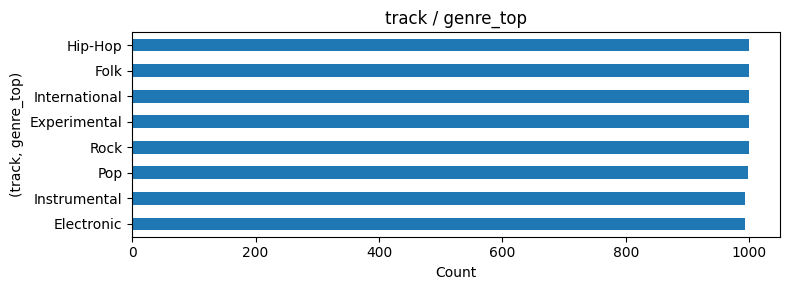

=== set / split (missing: 0 / 0.0%) ===
(set, split)
training      0.801
validation    0.100
test          0.099
Name: proportion, dtype: float64



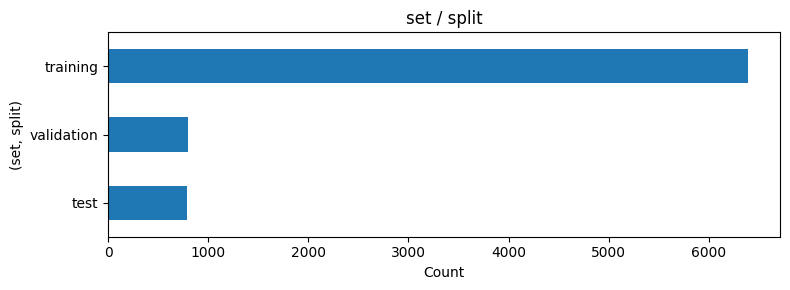

In [ ]:
# Categorical: Target Label & Dataset Split
cat_cols = [
    ('track', 'genre_top'),
    ('set', 'split'),
]

for col in cat_cols:
    print(f"=== {' / '.join(col)} (missing: {clean_tracks[col].isna().sum()} / {clean_tracks[col].isna().mean()*100:.1f}%) ===")
    print(clean_tracks[col].value_counts(normalize=True).round(3).head(15))
    print()
    clean_tracks[col].value_counts().head(15).plot.barh(figsize=(8, 3))
    plt.title(" / ".join(col))
    plt.xlabel("Count")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

**Observations (V.1):**
- **`track / genre_top`**: All 8 top-level genres are virtually balanced at ~12.4–12.5% each (0 missing values, 0 rare levels), making this an ideal multi-class classification target that requires no resampling or class-weight adjustments.
- **`set / split`**: The official benchmark partition is cleanly divided into 80.1% `training`, 10.0% `validation`, and 9.9% `test` (0 missing values), providing a standardized split for model training, hyperparameter tuning, and unbiased evaluation.

## **V.2 Audio File Technical Context (`clean_tracks`)**

Inspects `track / bit_rate` (since MP3 compression can alter high-frequency spectral features) and `track / duration` (confirming original track lengths before FMA's 30-second audio clipping).

count        mean        std       min       25%       50%  \
track bit_rate  7983.0  265391.509  60903.055  105237.0  214011.5  262289.0   
      duration  7983.0     228.849     98.432      60.0     161.0     215.0   

                     75%       max   skew  
track bit_rate  320000.0  322541.0 -0.722  
      duration     279.0     600.0  0.940

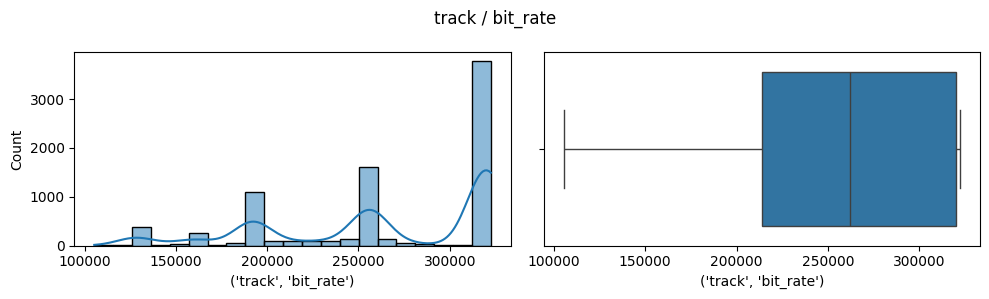

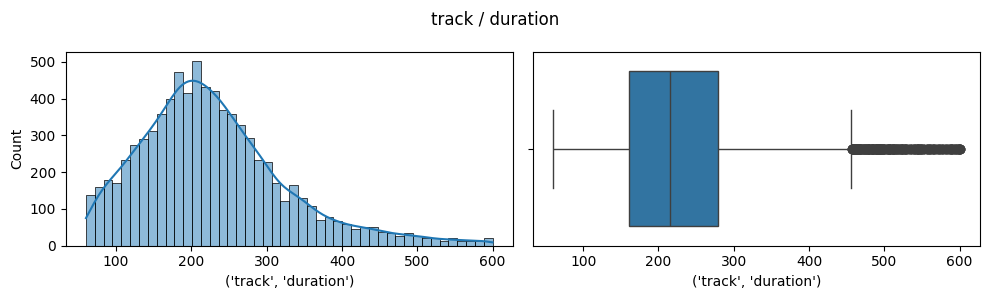

In [ ]:
# Numeric: Audio File Technical Context
num_cols = [
    ('track', 'bit_rate'),
    ('track', 'duration'),
]

display(clean_tracks[num_cols].describe().T.assign(skew=clean_tracks[num_cols].skew()).round(3))

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(clean_tracks[col], kde=True, ax=axes[0])
    sns.boxplot(x=clean_tracks[col], ax=axes[1])
    fig.suptitle(" / ".join(col))
    plt.tight_layout()
    plt.show()

**Observations (V.2):**
- **`track / bit_rate`**: Bit rate is moderately left-skewed (`skew = -0.72`), clustering near standard high-quality MP3 encodings with a median of 262.3 kbps (mean = 265.4 kbps, SD = 60.9 kbps, IQR = 106.0 kbps from 214.0 to 320.0 kbps). Values span 105.2 to 322.5 kbps with zero IQR outliers and discrete spikes at standard bit rates (128, 192, 256, and 320 kbps), meaning most tracks have high enough audio quality to preserve upper-frequency spectral features.
- **`track / duration`**: Full track duration is moderately right-skewed (`skew = 0.94`); the median of 215 s (~3.6 min; IQR = 118 s, 161–279 s) is a slightly better summary of center than the mean of 228.8 s (SD = 98.4 s). All cleaned tracks are at least 60 s long (well above FMA-Small's 30 s clip length), with 270 upper-tail outliers (3.4%) extending up to 600 s.

## **V.3 Spectral Shape & Brightness (`clean_features`)**

Examines primary `mean / 01` frequency-domain descriptors: `spectral_centroid` (brightness), `spectral_bandwidth` (frequency spread), `spectral_rolloff` (high-frequency cutoff), and `spectral_contrast` (peak-to-valley spectral separation).

,,,count,mean,std,min,25%,50%,75%,max,skew
feature,statistics,number,,,,,,,,,
spectral_centroid,mean,01,7983.0,1175.064,501.726,140.754,818.903,1125.441,1460.532,5575.108,1.038
spectral_bandwidth,mean,01,7983.0,1420.851,440.942,241.755,1119.570,1410.866,1700.045,3789.372,0.316
spectral_rolloff,mean,01,7983.0,2371.575,1112.917,167.247,1566.877,2262.460,3041.472,9401.771,0.796
spectral_contrast,mean,01,7983.0,20.587,3.392,10.350,18.274,20.262,22.533,38.504,0.675


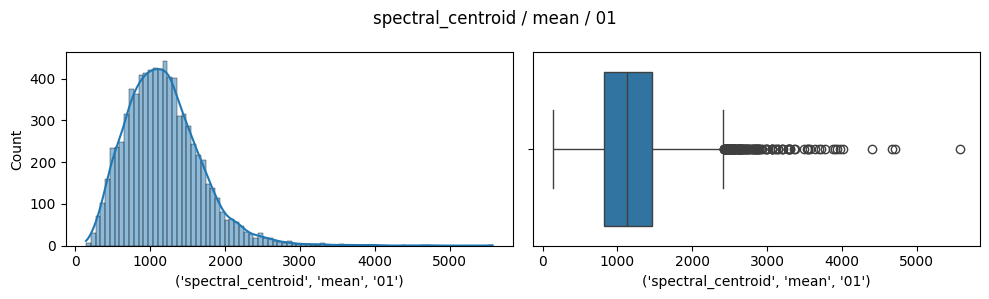

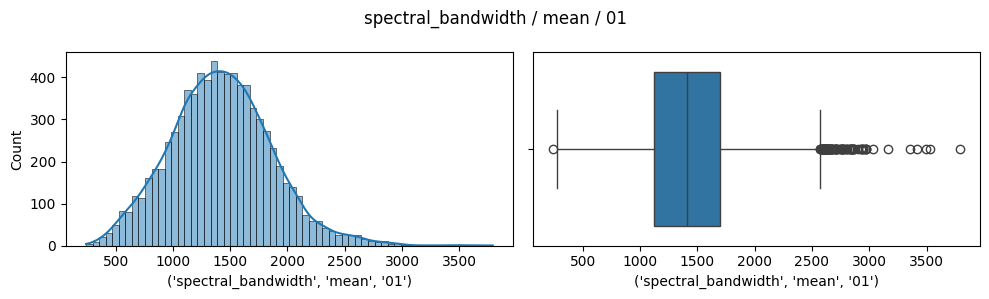

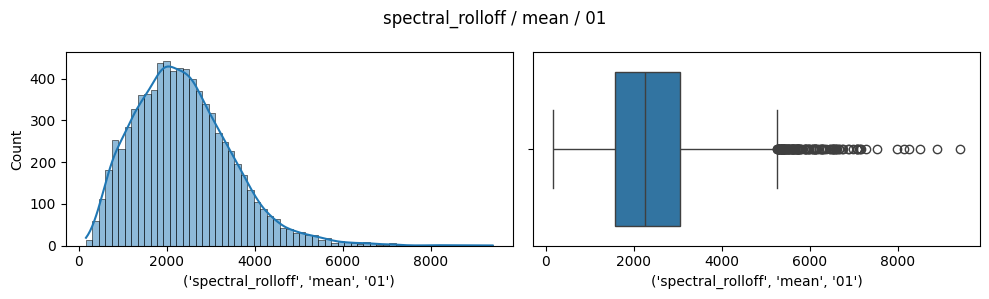

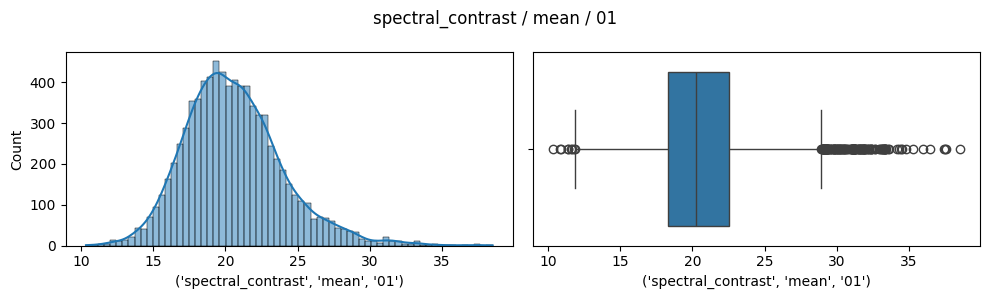

In [ ]:
# Numeric: Spectral Shape & Brightness
num_cols = [
    ('spectral_centroid', 'mean', '01'),
    ('spectral_bandwidth', 'mean', '01'),
    ('spectral_rolloff', 'mean', '01'),
    ('spectral_contrast', 'mean', '01'),
]

display(clean_features[num_cols].describe().T.assign(skew=clean_features[num_cols].skew()).round(3))

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(clean_features[col], kde=True, ax=axes[0])
    sns.boxplot(x=clean_features[col], ax=axes[1])
    fig.suptitle(" / ".join(col))
    plt.tight_layout()
    plt.show()

**Observations (V.3):**
- **`spectral_centroid / mean / 01`**: Mean spectral centroid is heavily right-skewed (`skew = 1.04`); the median of 1,125.4 Hz (IQR = 641.6 Hz) is slightly more robust than the mean of 1,175.1 Hz (SD = 501.7 Hz). Values span 140.8 to 5,575.1 Hz with 152 upper-tail outliers (1.9%) reflecting unusually bright, high-frequency tracks.
- **`spectral_bandwidth / mean / 01`**: Mean spectral bandwidth is approximately symmetric (`skew = 0.32`), so the mean (1,420.9 Hz, SD = 440.9 Hz) and median (1,410.9 Hz, IQR = 580.5 Hz) agree closely. Values range from 241.8 to 3,789.4 Hz with only 93 IQR outliers (1.2%, nearly all upper-tail).
- **`spectral_rolloff / mean / 01`**: Mean spectral rolloff is moderately right-skewed (`skew = 0.80`), with a median of 2,262.5 Hz (IQR = 1,474.6 Hz) slightly below the mean of 2,371.6 Hz (SD = 1,112.9 Hz). Values span 167.2 to 9,401.8 Hz, including 132 upper-tail outliers (1.7%) driven by high-frequency content.
- **`spectral_contrast / mean / 01`**: Mean spectral contrast is moderately right-skewed (`skew = 0.67`), centered around a median of 20.26 (IQR = 4.26) and a mean of 20.59 (SD = 3.39). Values range from 10.35 to 38.50 with 158 IQR outliers (2.0%; 9 low, 149 high), marking tracks with sharper harmonic peaks relative to background noise.

## **V.4 Timbre / MFCCs (`clean_features`)**

Inspects the first four Mel-Frequency Cepstral Coefficient means (`mfcc / mean / 01`–`04`), which capture overall spectral energy (`01`) and the core timbral spectral envelope (`02`–`04`)—typically the highest-importance feature family in music genre classification.

count     mean     std      min      25%      50%  \
feature statistics number                                                       
mfcc    mean       01      7983.0 -202.492  93.799 -985.114 -258.302 -191.371   
                   02      7983.0  146.495  31.802  -18.084  126.392  146.334   
                   03      7983.0  -11.212  29.901 -146.494  -30.105  -12.393   
                   04      7983.0   30.264  17.185  -68.000   21.173   31.741   

                               75%      max   skew  
feature statistics number                           
mfcc    mean       01     -136.644  138.372 -0.680  
                   02      166.384  268.769 -0.056  
                   03        6.250  117.980  0.218  
                   04       41.250  125.015 -0.661

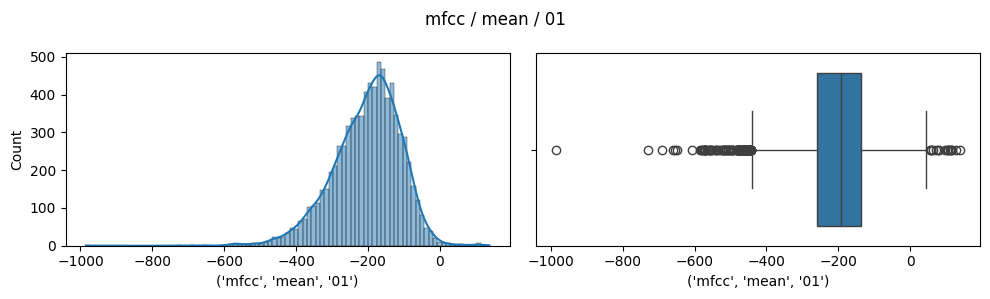

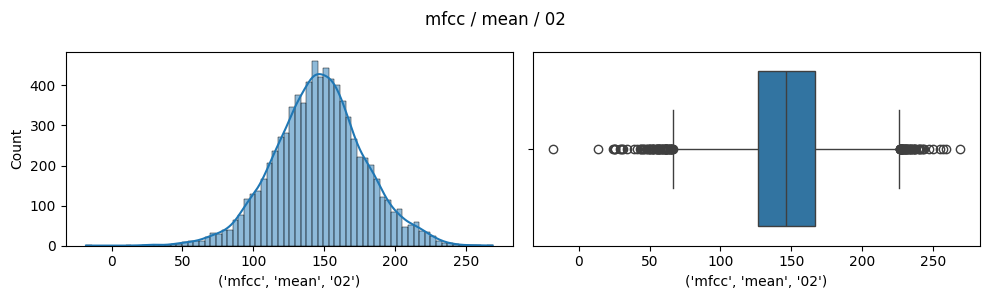

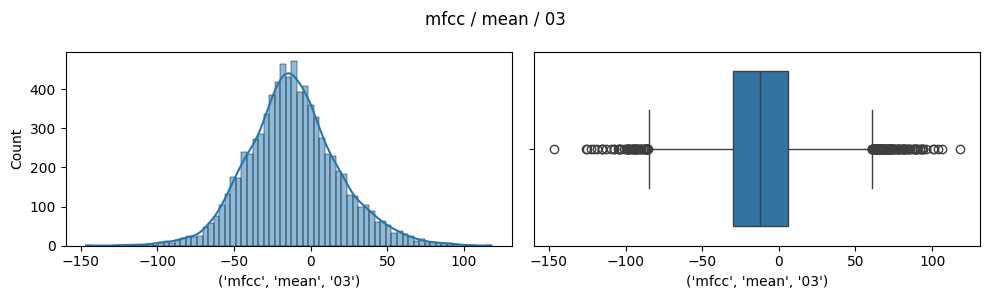

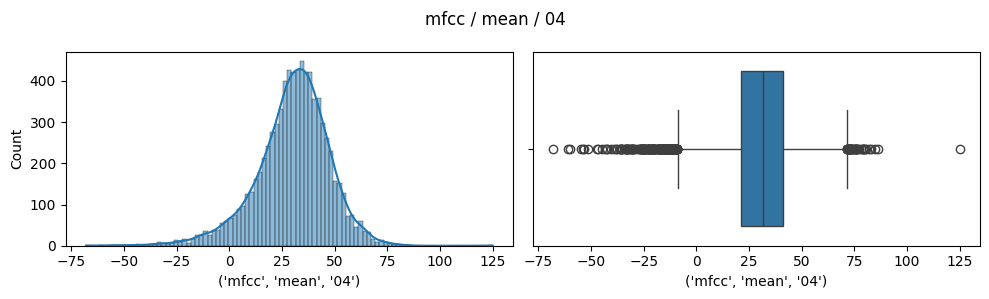

In [ ]:
# Numeric: Timbre / MFCCs
num_cols = [
    ('mfcc', 'mean', '01'),
    ('mfcc', 'mean', '02'),
    ('mfcc', 'mean', '03'),
    ('mfcc', 'mean', '04'),
]

display(clean_features[num_cols].describe().T.assign(skew=clean_features[num_cols].skew()).round(3))

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(clean_features[col], kde=True, ax=axes[0])
    sns.boxplot(x=clean_features[col], ax=axes[1])
    fig.suptitle(" / ".join(col))
    plt.tight_layout()
    plt.show()

**Observations (V.4):**
- **`mfcc / mean / 01`**: The first MFCC mean (overall spectral energy) is moderately left-skewed (`skew = -0.68`); the median of -191.4 (IQR = 121.7) is slightly higher than the mean of -202.5 (SD = 93.8). Values span -985.1 to 138.4 with 131 IQR outliers (1.6%; 114 low, 17 high), where extreme negative values correspond to quiet or sparse audio.
- **`mfcc / mean / 02`**: The second MFCC mean (broad low-to-high spectral slope) is nearly symmetric (`skew = -0.06`), with virtually identical mean (146.5, SD = 31.8) and median (146.3, IQR = 40.0). Values range from -18.1 to 268.8 with only 122 balanced IQR outliers (1.5%; 69 low, 53 high).
- **`mfcc / mean / 03`**: The third MFCC mean is approximately symmetric (`skew = 0.22`), centered near -12.4 (median; IQR = 36.4) and -11.2 (mean; SD = 29.9). Values span -146.5 to 118.0 with 185 IQR outliers (2.3%; 64 low, 121 high).
- **`mfcc / mean / 04`**: The fourth MFCC mean is moderately left-skewed (`skew = -0.66`); the median of 31.7 (IQR = 20.1) is slightly above the mean of 30.3 (SD = 17.2). Values span -68.0 to 125.0 with 254 IQR outliers (3.2%; 214 low, 40 high), showing a heavier lower tail than `mfcc 02` and `03`.

## **V.5 Energy, Percussion & Harmony (`clean_features`)**

Evaluates loudness (`rmse`), percussiveness/noisiness (`zcr`), pitch-class energy (`chroma_cens`), and tonal centroid (`tonnetz`) via their primary `mean / 01` descriptors.

,,,count,mean,std,min,25%,50%,75%,max,skew
feature,statistics,number,,,,,,,,,
rmse,mean,01,7983.0,4.565,2.478,0.000,2.734,4.283,6.008,21.608,1.336
zcr,mean,01,7983.0,0.051,0.028,0.003,0.032,0.046,0.063,0.630,3.477
chroma_cens,mean,01,7983.0,0.251,0.082,0.004,0.200,0.250,0.299,0.706,0.368
tonnetz,mean,01,7983.0,0.001,0.014,-0.095,-0.006,0.001,0.009,0.077,0.020


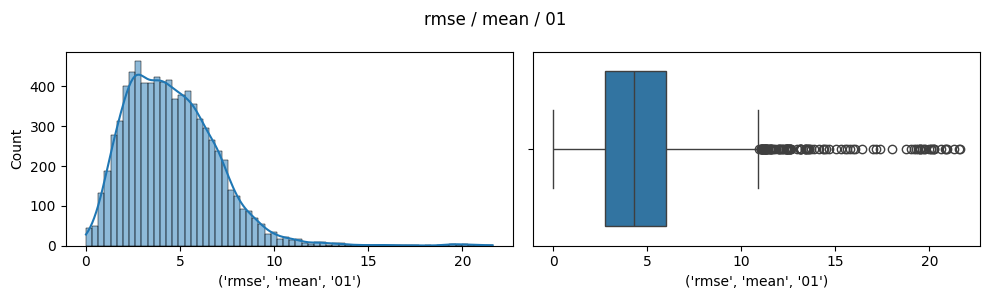

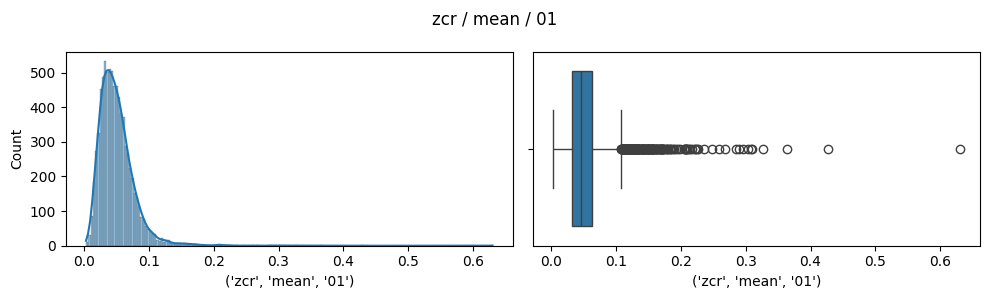

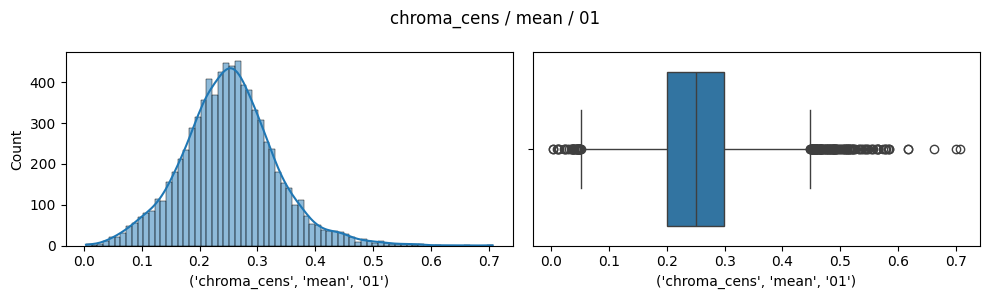

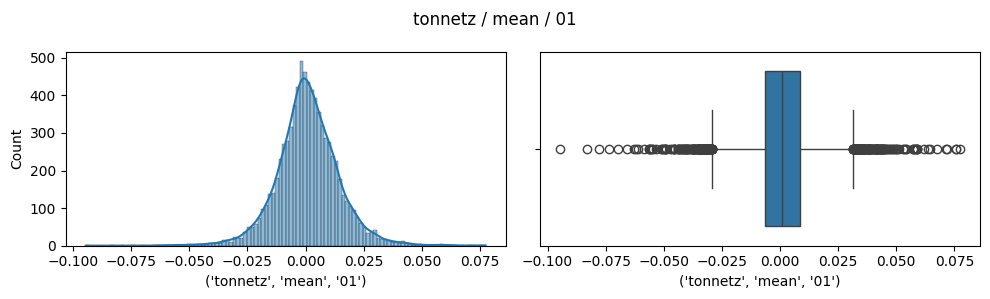

In [ ]:
# Numeric: Energy, Percussion & Harmony
num_cols = [
    ('rmse', 'mean', '01'),
    ('zcr', 'mean', '01'),
    ('chroma_cens', 'mean', '01'),
    ('tonnetz', 'mean', '01'),
]

display(clean_features[num_cols].describe().T.assign(skew=clean_features[num_cols].skew()).round(3))

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(clean_features[col], kde=True, ax=axes[0])
    sns.boxplot(x=clean_features[col], ax=axes[1])
    fig.suptitle(" / ".join(col))
    plt.tight_layout()
    plt.show()

**Observations (V.5):**
- **`rmse / mean / 01`**: Mean root-mean-square energy (loudness) is heavily right-skewed (`skew = 1.34`), with a median of 4.28 (IQR = 3.27) below the mean of 4.57 (SD = 2.48). Values span near-silence (0.000) to 21.61, with 113 upper-tail outliers (1.4%) representing unusually loud or heavily compressed tracks.
- **`zcr / mean / 01`**: Mean zero-crossing rate is heavily right-skewed (`skew = 3.48`); the median of 0.046 (IQR = 0.030) is a better summary than the mean of 0.051 (SD = 0.028). Values extend from 0.003 to 0.630 with 244 upper-tail outliers (3.1%) marking highly percussive, distorted, or noisy audio.
- **`chroma_cens / mean / 01`**: Mean chroma energy is approximately symmetric (`skew = 0.37`), with closely matching mean (0.251, SD = 0.082) and median (0.250, IQR = 0.099). It spans 0.004 to 0.706 with 183 IQR outliers (2.3%; 41 low, 142 high).
- **`tonnetz / mean / 01`**: Mean tonal centroid is tightly symmetric around zero (`skew = 0.02`; mean = 0.001, median = 0.001, SD = 0.014, IQR = 0.015). Despite clean centering, it shows moderately heavy tails with 280 symmetric IQR outliers (3.5%; 138 low, 142 high) spanning -0.095 to 0.077.

## **V.6 Temporal Variability (`clean_features`)**

Inspects frame-level standard deviation (`std / 01`) across loudness, spectral brightness, noisiness, and timbre to capture how much a track's acoustic properties fluctuate across its 30-second clip.

,,,count,mean,std,min,25%,50%,75%,max,skew
feature,statistics,number,,,,,,,,,
rmse,std,01,7983.0,2.197,1.023,0.000,1.435,2.077,2.820,8.914,0.768
spectral_centroid,std,01,7983.0,604.842,278.979,55.690,400.998,569.971,758.585,3023.301,1.126
zcr,std,01,7983.0,0.040,0.026,0.003,0.023,0.034,0.051,0.318,2.080
mfcc,std,01,7983.0,82.711,22.171,8.798,67.493,81.895,96.674,236.649,0.347


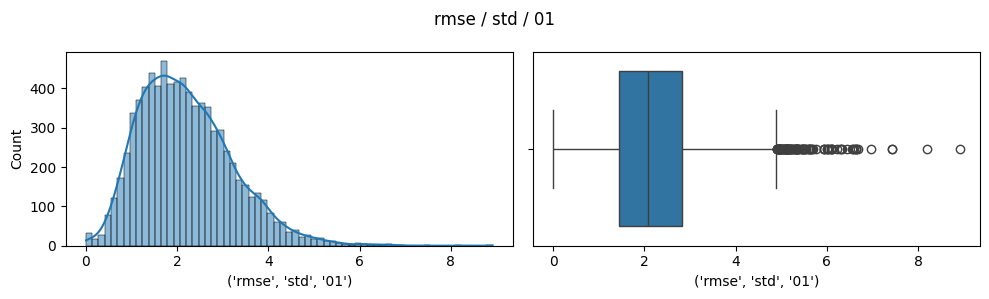

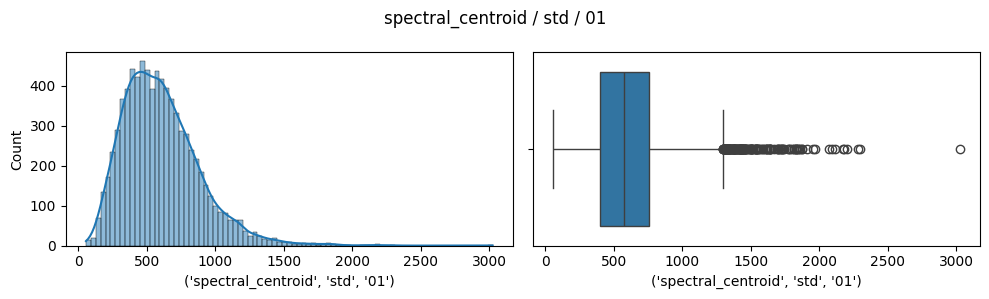

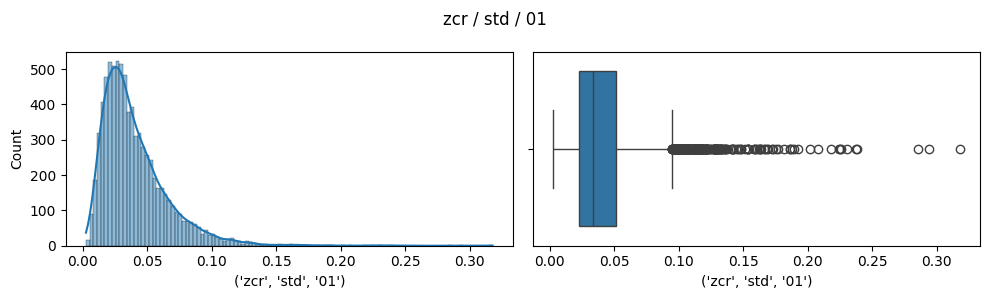

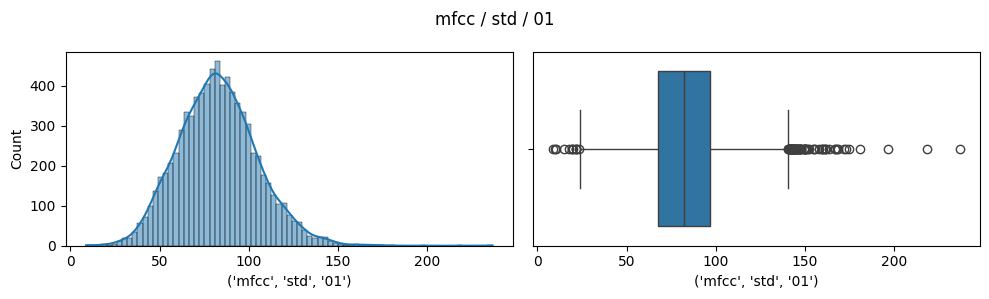

In [ ]:
# Numeric: Temporal Variability (std)
num_cols = [
    ('rmse', 'std', '01'),
    ('spectral_centroid', 'std', '01'),
    ('zcr', 'std', '01'),
    ('mfcc', 'std', '01'),
]

display(clean_features[num_cols].describe().T.assign(skew=clean_features[num_cols].skew()).round(3))

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(clean_features[col], kde=True, ax=axes[0])
    sns.boxplot(x=clean_features[col], ax=axes[1])
    fig.suptitle(" / ".join(col))
    plt.tight_layout()
    plt.show()

**Observations (V.6):**
- **`rmse / std / 01`**: Loudness variability is moderately right-skewed (`skew = 0.77`), with a median of 2.08 (IQR = 1.39) slightly below the mean of 2.20 (SD = 1.02). Values span 0.000 to 8.91 with 105 upper-tail outliers (1.3%), distinguishing tracks with sharp dynamic swings from steadily compressed tracks.
- **`spectral_centroid / std / 01`**: Brightness variability is heavily right-skewed (`skew = 1.13`); the median of 570.0 Hz (IQR = 357.6 Hz) is a better summary than the mean of 604.8 Hz (SD = 279.0 Hz). Values range from 55.7 to 3,023.3 Hz with 167 upper-tail outliers (2.1%) reflecting abrupt timbral shifts.
- **`zcr / std / 01`**: Zero-crossing rate variability is heavily right-skewed (`skew = 2.08`); the median of 0.034 (IQR = 0.029) better represents typical tracks than the mean of 0.040 (SD = 0.026). Values reach up to 0.318 with 310 upper-tail outliers (3.9%), capturing intermittent bursts of percussion or noise.
- **`mfcc / std / 01`**: First-MFCC variability is approximately symmetric (`skew = 0.35`), with closely matching mean (82.7, SD = 22.2) and median (81.9, IQR = 29.2). Values span 8.8 to 236.6 with only 88 IQR outliers (1.1%; 12 low, 76 high).

---

### **Key Takeaways for Audio-Feature Data Mining**
- **No Class-Imbalance Correction Needed**: `track / genre_top` is evenly balanced across all 8 genres (~12.5% each), and `set / split` provides a ready-to-use 80/10/10 benchmark partition.
- **Feature Scaling Is Essential**: Audio features span **6 orders of magnitude**—from `tonnetz / mean / 01` (~0.001) and `zcr / mean / 01` (~0.05) up to `spectral_rolloff / mean / 01` (~2,372)—so distance-, margin-, and gradient-based models (KNN, SVM, Logistic Regression, Neural Networks, PCA) require `StandardScaler` or `RobustScaler`.
- **Right-Skewed Features & Outliers**: Several acoustic predictors (`zcr`, `rmse`, `spectral_centroid`, and their `std` counterparts) exhibit right-skewness (`skew = 1.0–3.5`) with 1–4% upper-tail outliers; tree-based models (Random Forest, Gradient Boosting/XGBoost) handle these natively, while linear/distance-based models will benefit from power/log transforms or robust scaling.

# **VI. Bivariate and multivariate analysis**

# **VII. Type-specific analysis**
*(time, text, images, groups, as applies)*

# **VIII. Summary of findings**

# **IX. Limitations and next steps**

# **X. References**